# Le vrai prix de la ville
## Analyse descriptive de la relation entre proximité des transports en commun et prix de vente des appartements à Paris et en petite couronne (2021–2025)

### 1. Contexte et problématique

L'accessibilité aux transports en commun constitue une dimension importante de l'organisation urbaine. La proximité d'une station de métro, de RER, de tramway ou de train peut représenter un avantage pour les habitants en facilitant leurs déplacements quotidiens et leur accès aux différents pôles d'activité.

Cette accessibilité peut également être prise en compte dans la valorisation immobilière. Toutefois, cette relation n'est pas nécessairement uniforme : un logement situé à proximité immédiate d'une station ne présente pas forcément les mêmes caractéristiques qu'un logement situé à quelques centaines de mètres. De plus, les dynamiques immobilières peuvent différer entre Paris et les communes de sa petite couronne.

Ce projet cherche donc à étudier empiriquement la relation entre la distance aux stations de transport en commun et les prix de vente des appartements, à partir des transactions immobilières réellement observées entre 2021 et 2025.

**Problématique principale :**

Dans quelle mesure la proximité des stations de transport en commun est-elle associée aux prix de vente des appartements à Paris et en petite couronne ? Observe-t-on des distances particulièrement valorisées et ces relations sont-elles homogènes dans l'espace et dans le temps ?

### 2. Objectifs de l'étude

L'analyse s'organise autour de plusieurs questions :

- Comment les prix au mètre carré évoluent-ils selon la distance à la station la plus proche ?
- Les tendances observées à Paris sont-elles comparables à celles de la petite couronne ?
- Existe-t-il une tranche de distance présentant les prix médians les plus élevés ?
- Les résultats restent-ils comparables lorsque l'on utilise des tranches de distance plus fines ?
- La relation observée évolue-t-elle entre 2021 et 2025 ?
- Les tendances globales se retrouvent-elles à l'intérieur des communes ?
- Peut-on identifier un ou plusieurs intervalles de distance présentant une valorisation relativement favorable ?

### 3. Démarche méthodologique

Le travail repose exclusivement sur des données observées et sur des méthodes statistiques descriptives. Les principaux indicateurs mobilisés sont les effectifs, les moyennes, les médianes, les quantiles et les écarts relatifs.

Aucune méthode de prédiction ou de modélisation n'est utilisée. L'objectif n'est pas d'estimer un effet causal de la proximité des transports, mais de décrire les associations présentes dans les transactions observées et d'en discuter les limites.

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


### 4. Sources de données

L'étude s'appuie sur deux ensembles de données complémentaires.

**Les Demandes de valeurs foncières (DVF)**

Les données DVF recensent les transactions immobilières réalisées en France. Elles permettent notamment d'identifier la date de mutation, la localisation du bien, sa valeur foncière et certaines de ses caractéristiques physiques.

Dans le cadre de cette étude, nous nous intéressons exclusivement aux ventes d'appartements réalisées entre 2021 et 2025 dans les départements de Paris (75), des Hauts-de-Seine (92), de Seine-Saint-Denis (93) et du Val-de-Marne (94).

**Les données relatives aux stations de transport**

Les données des stations permettent de localiser les points d'accès aux différents réseaux de transport en commun. Elles apportent des informations complémentaires telles que le nom de la station, les lignes desservies, les modes de transport et, lorsque cette information est disponible, la date d'ouverture.

**Enrichissement des transactions**

Les données immobilières ont été rapprochées des données de transport afin d'associer à chaque transaction une station de référence et une distance correspondante.

La variable centrale de l'étude est donc la distance, exprimée en mètres, entre la localisation de la transaction et la station retenue comme la plus proche.

La base enrichie constitue le support des analyses descriptives présentées dans la suite du notebook.

In [30]:
DATA_PATH = Path("/home/onyxia/work/Projet_Data_2A_S1/data/processed/dvf_appartements_stations.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Fichier introuvable : {DATA_PATH.resolve()}\n"
        "Modifie DATA_PATH pour indiquer le chemin correct."
    )

df = pd.read_csv(DATA_PATH, low_memory=False)

print(f"Dimensions de la base : {df.shape[0]:,} lignes et {df.shape[1]} colonnes")
display(df.head())

Dimensions de la base : 319,947 lignes et 26 colonnes


,id_mutation,date_mutation,annee,code_departement,code_commune,nom_commune,code_postal,adresse,id_parcelle,valeur_fonciere,surface_reelle_bati,nombre_pieces_principales,n_dependances,prix_m2,log_prix_m2,longitude,latitude,id_station,nom_station,lignes_station,modes_station,nb_lignes_station,date_ouverture_station,dist_station_m,classe_dist,nb_stations_voisinage
0,2021-1715667,2021-01-04,2021,75,75110,Paris 10e Arrondissement,"75,010.00",12 RUE DE BELZUNCE,75110000AB0070,"420,000.00",29.00,1.00,1,"14,482.76",9.58,2.35,48.88,71363,Poissonnière,METRO 7,METRO,1,1910-11-05,366.15,300-400 m,3
1,2021-1715693,2021-01-04,2021,75,75109,Paris 9e Arrondissement,"75,009.00",1 RUE DE CHANTILLY,75109000BE0090,"879,600.00",72.00,4.00,0,"12,216.67",9.41,2.35,48.88,71363,Poissonnière,METRO 7,METRO,1,1910-11-05,178.73,100-200 m,2
2,2021-1715714,2021-01-04,2021,75,75110,Paris 10e Arrondissement,"75,010.00",17 RUE D ENGHIEN,75110000AV0010,"430,000.00",32.00,2.00,0,"13,437.50",9.51,2.35,48.87,71320,Bonne Nouvelle,"METRO 8, METRO 9",METRO,2,1931-05-05,265.73,200-300 m,3
3,2021-1716484,2021-01-04,2021,75,75111,Paris 11e Arrondissement,"75,011.00",110 RUE DE LA FOLIE MERICOURT,75111000AB0032,"270,000.00",23.00,1.00,0,"11,739.13",9.37,2.37,48.87,71840,Goncourt,METRO 11,METRO,1,1935-04-28,258.12,200-300 m,3
4,2021-1718659,2021-01-04,2021,75,75113,Paris 13e Arrondissement,"75,013.00",33 RUE BOUSSINGAULT,75113000DK0015,"475,000.00",49.00,2.00,1,"9,693.88",9.18,2.34,48.82,70623,Cité universitaire,RER B,RER,1,1846-06-23,485.18,400-500 m,1


In [31]:
print("Colonnes disponibles :")
print(df.columns.tolist())

print("\nTypes des variables :")
display(df.dtypes.to_frame("Type"))

print("\nInformations générales :")
df.info()

Colonnes disponibles :
['id_mutation', 'date_mutation', 'annee', 'code_departement', 'code_commune', 'nom_commune', 'code_postal', 'adresse', 'id_parcelle', 'valeur_fonciere', 'surface_reelle_bati', 'nombre_pieces_principales', 'n_dependances', 'prix_m2', 'log_prix_m2', 'longitude', 'latitude', 'id_station', 'nom_station', 'lignes_station', 'modes_station', 'nb_lignes_station', 'date_ouverture_station', 'dist_station_m', 'classe_dist', 'nb_stations_voisinage']

Types des variables :


,Type
id_mutation,str
date_mutation,str
annee,int64
code_departement,int64
code_commune,int64
nom_commune,str
code_postal,float64
adresse,str
id_parcelle,str
valeur_fonciere,float64



Informations générales :
<class 'pandas.DataFrame'>
RangeIndex: 319947 entries, 0 to 319946
Data columns (total 26 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   id_mutation                319947 non-null  str    
 1   date_mutation              319947 non-null  str    
 2   annee                      319947 non-null  int64  
 3   code_departement           319947 non-null  int64  
 4   code_commune               319947 non-null  int64  
 5   nom_commune                319947 non-null  str    
 6   code_postal                319943 non-null  float64
 7   adresse                    319947 non-null  str    
 8   id_parcelle                319947 non-null  str    
 9   valeur_fonciere            319947 non-null  float64
 10  surface_reelle_bati        319947 non-null  float64
 11  nombre_pieces_principales  319659 non-null  float64
 12  n_dependances              319947 non-null  int64  
 13  prix_m2       

### 5. Préparation et contrôle de la qualité des données

Avant de procéder aux comparaisons, il est nécessaire de vérifier la cohérence de la base finale.

Les contrôles portent principalement sur :

- la présence des variables indispensables à l'analyse ;
- le format des dates et des variables numériques ;
- les valeurs manquantes ;
- les éventuelles valeurs aberrantes ou incohérentes ;
- la cohérence des départements et des années étudiées.

Il convient de rappeler que la base utilisée est déjà issue d'un processus de sélection et de nettoyage des transactions. Les contrôles ci-dessous permettent de vérifier sa cohérence avant l'analyse, sans refaire arbitrairement les traitements déjà effectués.

In [32]:
required_columns = [
    "annee",
    "code_departement",
    "code_commune",
    "nom_commune",
    "valeur_fonciere",
    "surface_reelle_bati",
    "prix_m2",
    "dist_station_m"
]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Colonnes indispensables absentes : {missing_columns}")

# Conversion des variables numériques
numeric_columns = [
    "annee",
    "valeur_fonciere",
    "surface_reelle_bati",
    "prix_m2",
    "dist_station_m"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Conversion de la date si disponible
if "date_mutation" in df.columns:
    df["date_mutation"] = pd.to_datetime(
        df["date_mutation"], errors="coerce"
    )

# Restriction aux départements étudiés
departements = ["75", "92", "93", "94"]

df["code_departement"] = (
    df["code_departement"].astype(str).str.replace(".0", "", regex=False).str.zfill(2)
)

df = df[df["code_departement"].isin(departements)].copy()

# Restriction à la période
df = df[df["annee"].between(2021, 2025)].copy()

# Exclusion des observations sans prix ou distance exploitable
df = df[
    df["prix_m2"].notna()
    & df["dist_station_m"].notna()
    & (df["prix_m2"] > 0)
    & (df["dist_station_m"] >= 0)
].copy()

# Identification de la zone géographique
df["zone"] = np.where(
    df["code_departement"] == "75",
    "Paris",
    "Petite couronne"
)

print(f"Nombre d'observations retenues : {len(df):,}")
print("\nRépartition géographique :")
display(df["zone"].value_counts().to_frame("Nombre de transactions"))

Nombre d'observations retenues : 319,947

Répartition géographique :


,Nombre de transactions
zone,
Petite couronne,176705
Paris,143242


In [33]:
quality = pd.DataFrame({
    "Valeurs manquantes": df.isna().sum(),
    "Part manquante (%)": df.isna().mean() * 100
}).sort_values("Part manquante (%)", ascending=False)

display(quality)

print("Nombre de lignes entièrement dupliquées :", df.duplicated().sum())

if "id_mutation" in df.columns:
    print(
        "Nombre d'identifiants de mutation distincts :",
        df["id_mutation"].nunique()
    )

print("\nRésumé des variables principales :")
display(
    df[["prix_m2", "dist_station_m", "valeur_fonciere", "surface_reelle_bati"]]
    .describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95])
)

,Valeurs manquantes,Part manquante (%)
nombre_pieces_principales,288,0.09
code_postal,4,0.00
date_mutation,0,0.00
annee,0,0.00
code_departement,0,0.00
code_commune,0,0.00
nom_commune,0,0.00
adresse,0,0.00
id_parcelle,0,0.00
valeur_fonciere,0,0.00


Nombre de lignes entièrement dupliquées : 0
Nombre d'identifiants de mutation distincts : 319947

Résumé des variables principales :


,prix_m2,dist_station_m,valeur_fonciere,surface_reelle_bati
count,"319,947.00","319,947.00","319,947.00","319,947.00"
mean,"8,007.48",606.22,"443,243.40",54.83
std,"3,651.12",612.53,"422,066.86",30.85
min,"1,500.00",1.39,"14,000.00",9.00
5%,"2,875.00",98.29,"120,000.00",18.00
25%,"5,204.85",215.93,"210,000.00",32.00
50%,"7,750.00",372.03,"320,600.00",50.00
75%,"10,316.95",765.21,"520,000.00",70.00
95%,"14,074.07","1,942.38","1,172,849.00",109.00
max,"30,000.00","5,743.34","8,500,000.00",300.00


### 6. Première description de la base étudiée

Cette première étape vise à caractériser l'échantillon sur lequel reposent les résultats.

La répartition des transactions entre Paris et la petite couronne permet de mesurer le poids relatif des deux territoires dans l'étude. La distribution des prix au mètre carré donne ensuite une première indication de l'hétérogénéité du marché immobilier.

La médiane sera privilégiée dans les comparaisons de prix. Contrairement à la moyenne, elle est moins sensible à l'influence de transactions exceptionnellement élevées ou faibles.

Les résultats de cette partie décrivent la composition de l'échantillon ; ils ne doivent pas être interprétés comme une représentation exhaustive de l'ensemble du parc immobilier.

In [34]:
description_zone = (
    df.groupby("zone")
      .agg(
          nombre_transactions=("prix_m2", "size"),
          prix_median=("prix_m2", "median"),
          prix_moyen=("prix_m2", "mean"),
          ecart_type=("prix_m2", "std"),
          distance_mediane=("dist_station_m", "median"),
          distance_moyenne=("dist_station_m", "mean")
      )
      .reset_index()
)

display(description_zone)

,zone,nombre_transactions,prix_median,prix_moyen,ecart_type,distance_mediane,distance_moyenne
0,Paris,143242,"10,313.74","10,615.93","3,159.81",225.68,242.07
1,Petite couronne,176705,"5,625.00","5,892.99","2,461.04",694.44,901.41


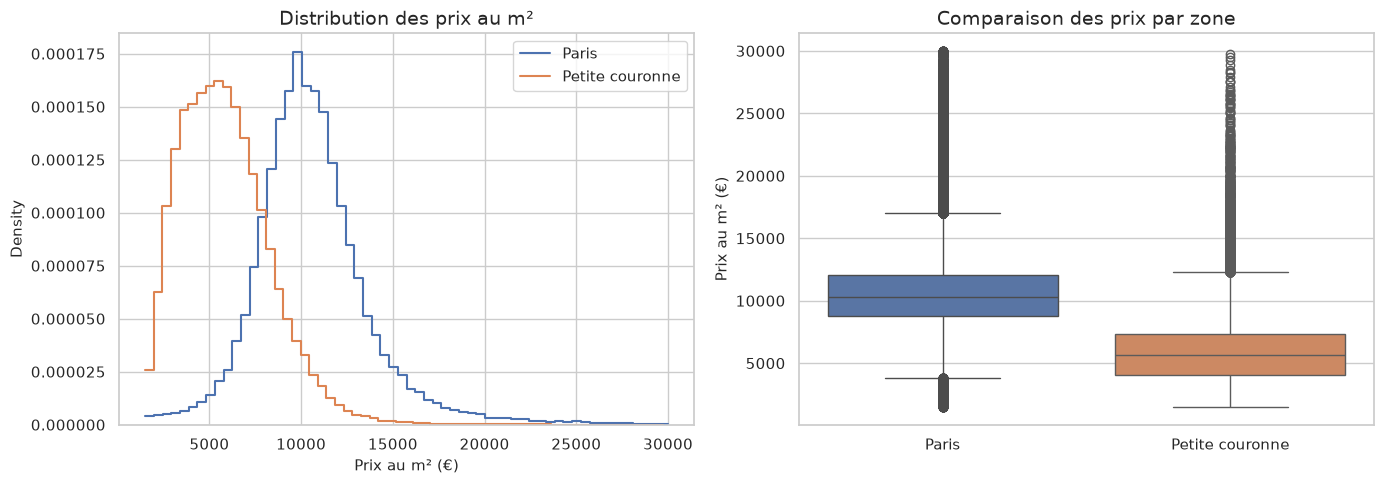

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for zone, couleur in zip(
    ["Paris", "Petite couronne"],
    ["#1f77b4", "#e67e22"]
):
    subset = df[df["zone"] == zone]

    sns.histplot(
        subset["prix_m2"],
        bins=60,
        stat="density",
        element="step",
        fill=False,
        label=zone,
        ax=axes[0]
    )

    sns.boxplot(
        data=subset,
        x="zone",
        y="prix_m2",
        ax=axes[1]
    )

axes[0].set_title("Distribution des prix au m²")
axes[0].set_xlabel("Prix au m² (€)")
axes[0].legend()

axes[1].set_title("Comparaison des prix par zone")
axes[1].set_xlabel("")
axes[1].set_ylabel("Prix au m² (€)")

plt.tight_layout()
plt.show()

### 7. Relation générale entre distance et prix de vente

Nous abordons maintenant la question centrale du projet : comment les prix des appartements évoluent-ils en fonction de leur distance à la station de transport la plus proche ?

Pour répondre à cette question, les distances sont regroupées en intervalles. Cette représentation permet de comparer des ensembles de transactions présentant des niveaux de proximité similaires.

L'indicateur principal retenu est le prix médian au mètre carré de chaque intervalle. Les effectifs sont systématiquement présentés afin de tenir compte de la taille des groupes et d'éviter de donner la même importance à des résultats fondés sur quelques transactions seulement.

Une première analyse globale est réalisée, avant de distinguer Paris et la petite couronne.

In [36]:
bins_100 = [
    0, 100, 200, 300, 400, 600, 800, 1000, 1500, np.inf
]

labels_100 = [
    "0-100", "100-200", "200-300", "300-400",
    "400-600", "600-800", "800-1000",
    "1000-1500", "1500+"
]

df["tranche_100m"] = pd.cut(
    df["dist_station_m"],
    bins=bins_100,
    labels=labels_100,
    right=False,
    include_lowest=True
)

analyse_100 = (
    df.groupby(["zone", "tranche_100m"], observed=False)
      .agg(
          nombre_transactions=("prix_m2", "count"),
          prix_median=("prix_m2", "median"),
          prix_moyen=("prix_m2", "mean")
      )
      .reset_index()
)

display(analyse_100)

,zone,tranche_100m,nombre_transactions,prix_median,prix_moyen
0,Paris,0-100,14548,"10,312.50","10,584.93"
1,Paris,100-200,43964,"10,434.78","10,711.41"
2,Paris,200-300,44319,"10,416.67","10,736.69"
3,Paris,300-400,25308,"10,242.72","10,575.91"
4,Paris,400-600,14082,"9,855.26","10,152.10"
5,Paris,600-800,1021,"9,101.56","9,093.95"
6,Paris,800-1000,0,NaN,NaN
7,Paris,1000-1500,0,NaN,NaN
8,Paris,1500+,0,NaN,NaN
9,Petite couronne,0-100,2287,"6,666.67","6,952.64"


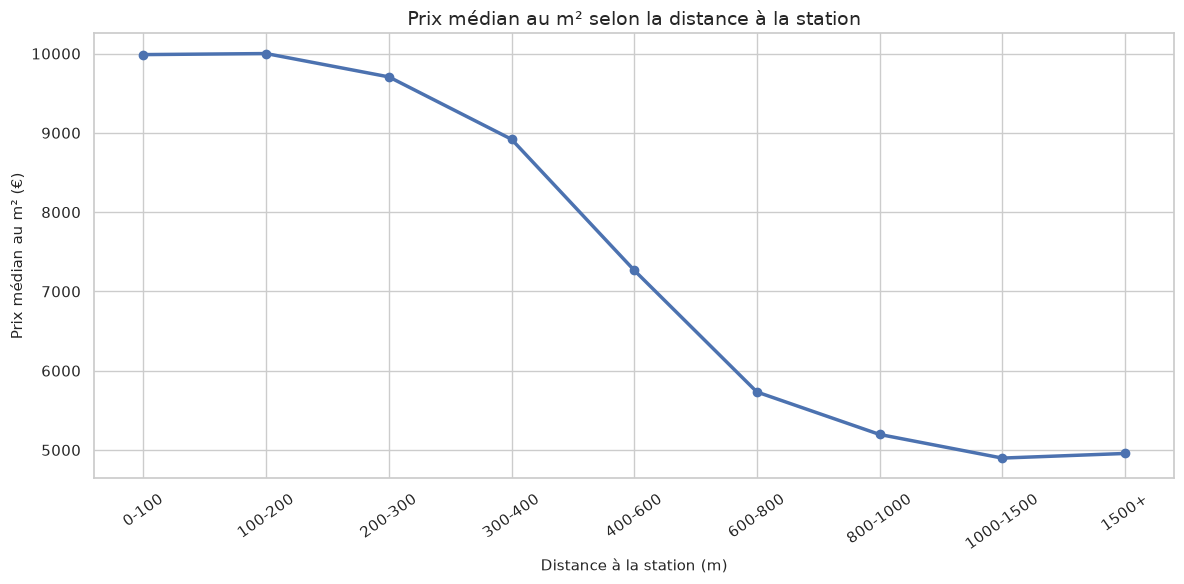

,tranche_100m,nombre_transactions,prix_median
0,0-100,16835,"9,986.79"
1,100-200,52808,"10,000.00"
2,200-300,58722,"9,705.72"
3,300-400,41974,"8,918.89"
4,400-600,47567,"7,266.67"
5,600-800,25979,"5,731.71"
6,800-1000,18503,"5,196.08"
7,1000-1500,28237,"4,897.96"
8,1500+,29322,"4,956.20"


In [37]:
global_100 = (
    df.groupby("tranche_100m", observed=False)
      .agg(
          nombre_transactions=("prix_m2", "count"),
          prix_median=("prix_m2", "median")
      )
      .reset_index()
)

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(
    global_100["tranche_100m"].astype(str),
    global_100["prix_median"],
    marker="o",
    linewidth=2.5
)

ax1.set_title("Prix médian au m² selon la distance à la station")
ax1.set_xlabel("Distance à la station (m)")
ax1.set_ylabel("Prix médian au m² (€)")
ax1.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

display(global_100)

### 7.1. Premiers résultats à l'échelle de l'ensemble de la zone étudiée

La comparaison des tranches de distance met en évidence une association entre proximité des transports et prix immobiliers.

Les prix médians sont particulièrement élevés dans les premières centaines de mètres autour des stations. Ils diminuent ensuite globalement avec l'éloignement, même si cette évolution n'est pas strictement régulière sur toutes les tranches.

Cette première observation suggère que la proximité des transports constitue une caractéristique associée à la valorisation des appartements.

Cependant, une comparaison globale peut masquer des différences territoriales importantes. Paris et la petite couronne présentent des structures urbaines, des niveaux de prix et des distributions de distances très différents. Il est donc nécessaire de conduire les analyses séparément.

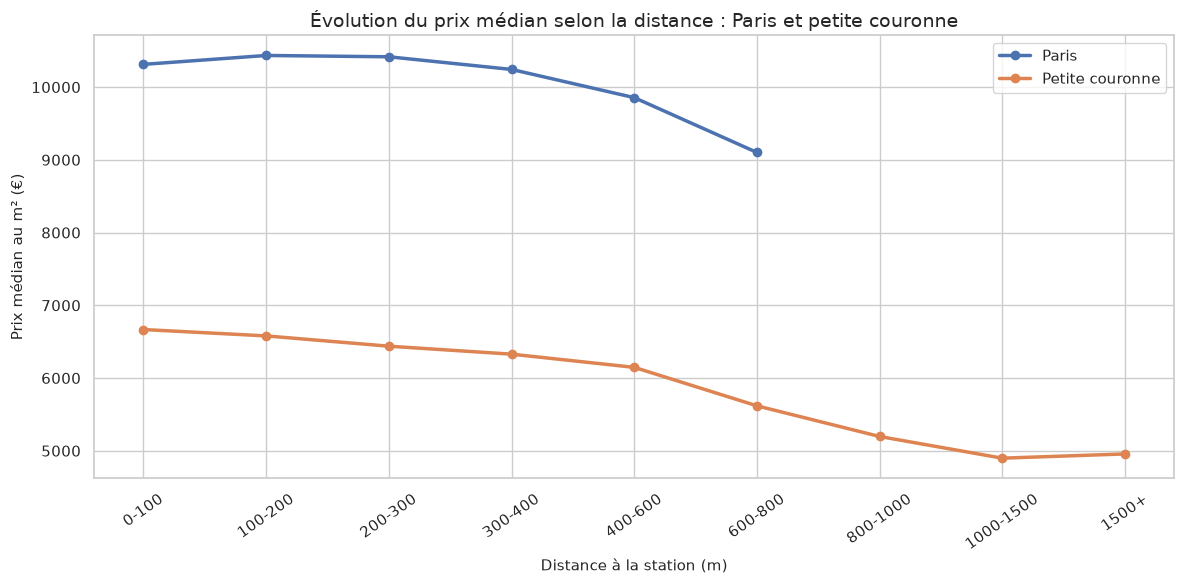

In [38]:
fig, ax = plt.subplots(figsize=(12, 6))

for zone in ["Paris", "Petite couronne"]:
    temp = analyse_100[analyse_100["zone"] == zone]

    ax.plot(
        temp["tranche_100m"].astype(str),
        temp["prix_median"],
        marker="o",
        linewidth=2.5,
        label=zone
    )

ax.set_title("Évolution du prix médian selon la distance : Paris et petite couronne")
ax.set_xlabel("Distance à la station (m)")
ax.set_ylabel("Prix médian au m² (€)")
ax.tick_params(axis="x", rotation=35)
ax.legend()

plt.tight_layout()
plt.show()

### 7.2. Des dynamiques différentes entre Paris et la petite couronne

La distinction territoriale fait apparaître deux profils différents.

**À Paris**, les prix médians les plus élevés sont observés dans la tranche de 100 à 200 mètres, avec un niveau d'environ 10 435 €/m². Les prix restent relativement proches sur les tranches de 100 à 300 mètres, ce qui suggère l'existence d'un plateau de valorisation à proximité des stations. Au-delà de 300 à 400 mètres, la baisse devient plus visible.

Il faut toutefois noter que les transactions parisiennes sont très concentrées autour des stations : les observations deviennent rares au-delà de 600 mètres et aucune transaction n'est observée au-delà de 800 mètres dans l'échantillon étudié.

**En petite couronne**, le niveau médian le plus élevé parmi les tranches de 100 mètres apparaît entre 0 et 100 mètres, avec environ 6 667 €/m². La baisse des prix est ensuite plus progressive et s'étend sur des distances plus importantes.

Ces différences montrent que la relation entre proximité et prix dépend du contexte territorial. Il serait donc inapproprié de rechercher une distance optimale unique pour l'ensemble de la zone étudiée.

### 8. Analyse à granularité fine : tranches de 50 mètres

Les tranches de 100 mètres permettent de dégager les grandes tendances, mais elles peuvent masquer certaines variations locales.

Pour approfondir l'analyse, nous réduisons la largeur des intervalles à 50 mètres. Cette approche permet notamment de vérifier si le maximum observé dans une tranche de 100 mètres correspond à une tendance relativement continue ou s'il est concentré dans un intervalle plus restreint.

Cette précision supplémentaire doit toutefois être interprétée avec prudence : la réduction de la largeur des intervalles entraîne une diminution des effectifs par groupe. Les résultats des tranches fines sont donc toujours accompagnés du nombre de transactions correspondant.

In [39]:
# Tranches fines jusqu'à 1 000 mètres
edges_50 = list(range(0, 1001, 50)) + [1500, 2000, np.inf]

labels_50 = [
    f"{edges_50[i]}-{edges_50[i+1]}"
    for i in range(len(edges_50)-1)
]

labels_50[-1] = "2000+"

df["tranche_50m"] = pd.cut(
    df["dist_station_m"],
    bins=edges_50,
    labels=labels_50,
    right=False,
    include_lowest=True
)

analyse_50 = (
    df.groupby(["zone", "tranche_50m"], observed=False)
      .agg(
          nombre_transactions=("prix_m2", "count"),
          prix_median=("prix_m2", "median"),
          prix_moyen=("prix_m2", "mean")
      )
      .reset_index()
)

display(analyse_50)

,zone,tranche_50m,nombre_transactions,prix_median,prix_moyen
0,Paris,0-50,2891,"10,265.56","10,534.93"
1,Paris,50-100,11657,"10,326.11","10,597.33"
2,Paris,100-150,18762,"10,460.77","10,731.86"
3,Paris,150-200,25202,"10,416.67","10,696.19"
4,Paris,200-250,24499,"10,490.20","10,784.25"
5,Paris,250-300,19820,"10,333.33","10,677.90"
6,Paris,300-350,14402,"10,293.26","10,622.49"
7,Paris,350-400,10906,"10,181.82","10,514.40"
8,Paris,400-450,6987,"10,079.31","10,419.50"
9,Paris,450-500,3512,"9,879.83","10,151.48"


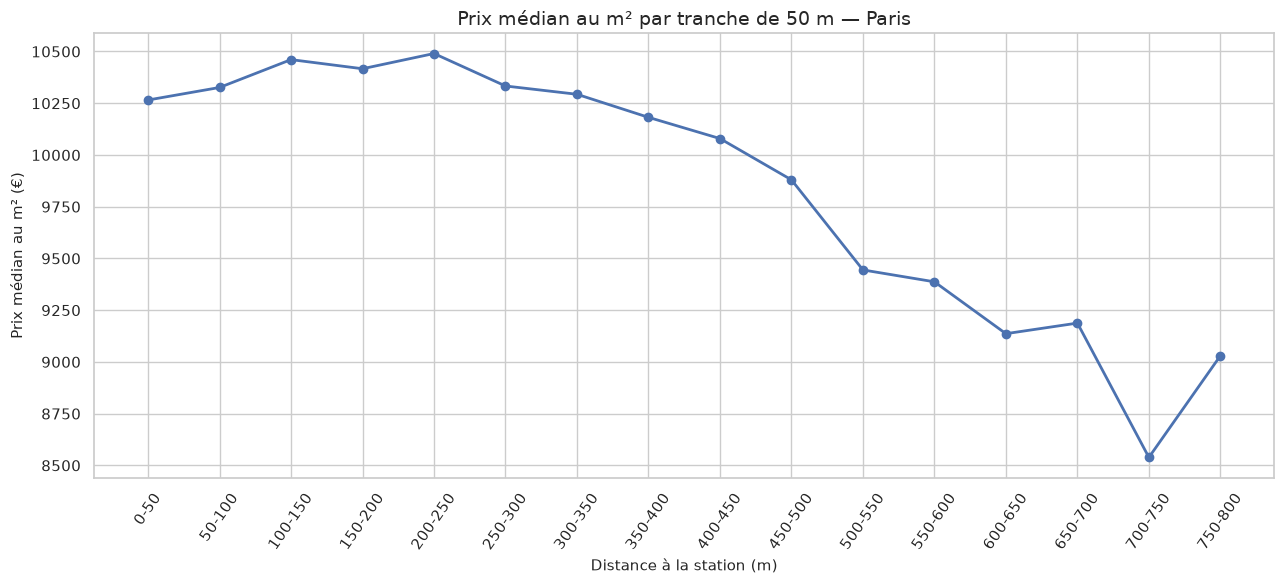

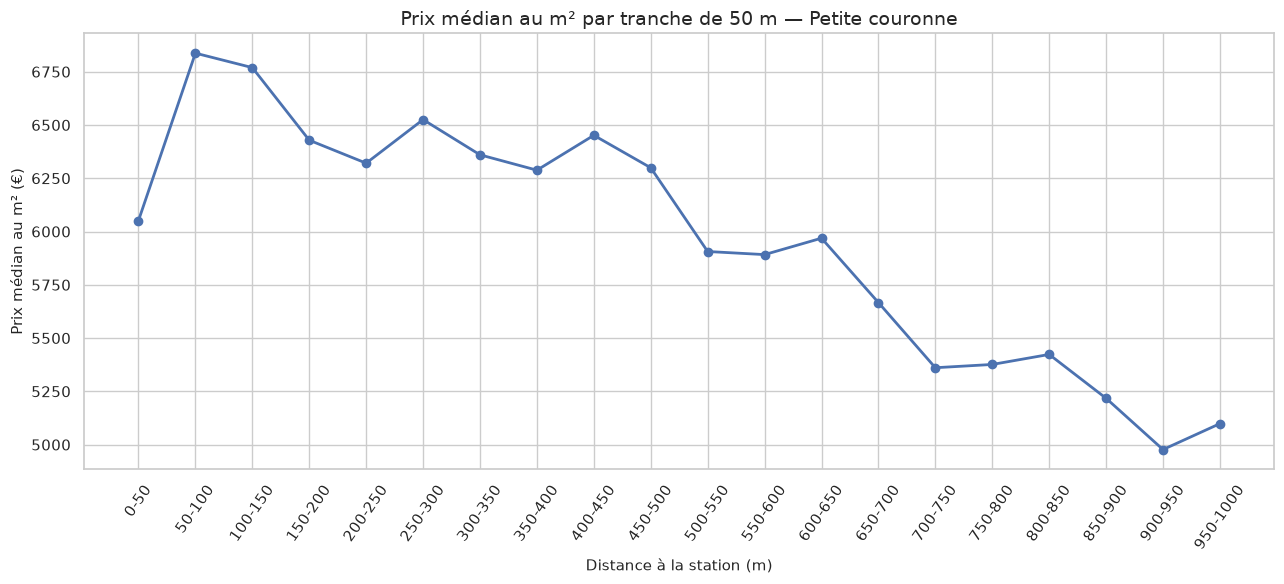

In [40]:
for zone in ["Paris", "Petite couronne"]:
    temp = analyse_50[
        (analyse_50["zone"] == zone)
        & (analyse_50["nombre_transactions"] > 0)
    ].copy()

    # On se concentre sur les distances jusqu'à 1 000 m
    temp = temp.iloc[:20]

    fig, ax1 = plt.subplots(figsize=(13, 6))

    ax1.plot(
        temp["tranche_50m"].astype(str),
        temp["prix_median"],
        marker="o",
        linewidth=2
    )

    ax1.set_title(f"Prix médian au m² par tranche de 50 m — {zone}")
    ax1.set_xlabel("Distance à la station (m)")
    ax1.set_ylabel("Prix médian au m² (€)")
    ax1.tick_params(axis="x", rotation=55)

    plt.tight_layout()
    plt.show()

In [41]:
for zone in ["Paris", "Petite couronne"]:
    temp = analyse_50[
        (analyse_50["zone"] == zone)
        & (analyse_50["nombre_transactions"] >= 100)
    ].copy()

    temp = temp.sort_values("prix_median", ascending=False)

    print(f"\n{zone} — Tranches les plus valorisées")
    display(temp.head(5))


Paris — Tranches les plus valorisées


,zone,tranche_50m,nombre_transactions,prix_median,prix_moyen
4,Paris,200-250,24499,"10,490.20","10,784.25"
2,Paris,100-150,18762,"10,460.77","10,731.86"
3,Paris,150-200,25202,"10,416.67","10,696.19"
5,Paris,250-300,19820,"10,333.33","10,677.90"
1,Paris,50-100,11657,"10,326.11","10,597.33"



Petite couronne — Tranches les plus valorisées


,zone,tranche_50m,nombre_transactions,prix_median,prix_moyen
24,Petite couronne,50-100,1804,"6,837.10","7,031.68"
25,Petite couronne,100-150,3607,"6,769.23","6,888.33"
28,Petite couronne,250-300,7620,"6,525.23","6,765.42"
31,Petite couronne,400-450,8690,"6,451.61","6,675.06"
26,Petite couronne,150-200,5237,"6,428.57","6,610.34"


### 8.1. Ce que révèle le découpage en tranches de 50 mètres

L'analyse fine permet de préciser les résultats obtenus avec les intervalles de 100 mètres.

À Paris, les prix médians les plus élevés se concentrent autour de 100 à 250 mètres, avec un maximum observé dans la tranche de 200 à 250 mètres dans l'analyse fine précédente. Les transactions situées entre 100 et 300 mètres présentent globalement des niveaux élevés. La tranche la plus proche de la station n'est donc pas systématiquement celle qui affiche le prix médian le plus important.

En petite couronne, les résultats sont plus irréguliers à très courte distance. La tranche de 0 à 50 mètres présente notamment un effectif plus limité et un prix médian inférieur à celui de la tranche de 50 à 100 mètres dans les résultats précédemment calculés. Au-delà, une tendance générale à la diminution des prix apparaît, même si certaines fluctuations subsistent.

Cette analyse confirme l'intérêt d'étudier plusieurs niveaux de granularité. Elle montre aussi pourquoi il serait excessif de considérer le maximum d'une seule tranche fine comme une distance optimale définitive.

### 9. Évolution de la relation entre 2021 et 2025

Les marchés immobiliers évoluent dans le temps. Une variation du prix au mètre carré entre deux années peut être liée à de nombreux facteurs économiques et immobiliers qui ne sont pas directement associés à la proximité des transports.

Il est donc nécessaire de vérifier si les profils observés selon la distance se retrouvent au cours des différentes années.

Cette analyse consiste à comparer, pour chaque année et chaque zone géographique, les prix médians des différentes tranches de distance.

Une seconde représentation exprimera les prix de chaque tranche relativement à leur niveau de 2021. Elle permettra de visualiser les évolutions temporelles sans confondre les niveaux de prix très différents entre les distances.

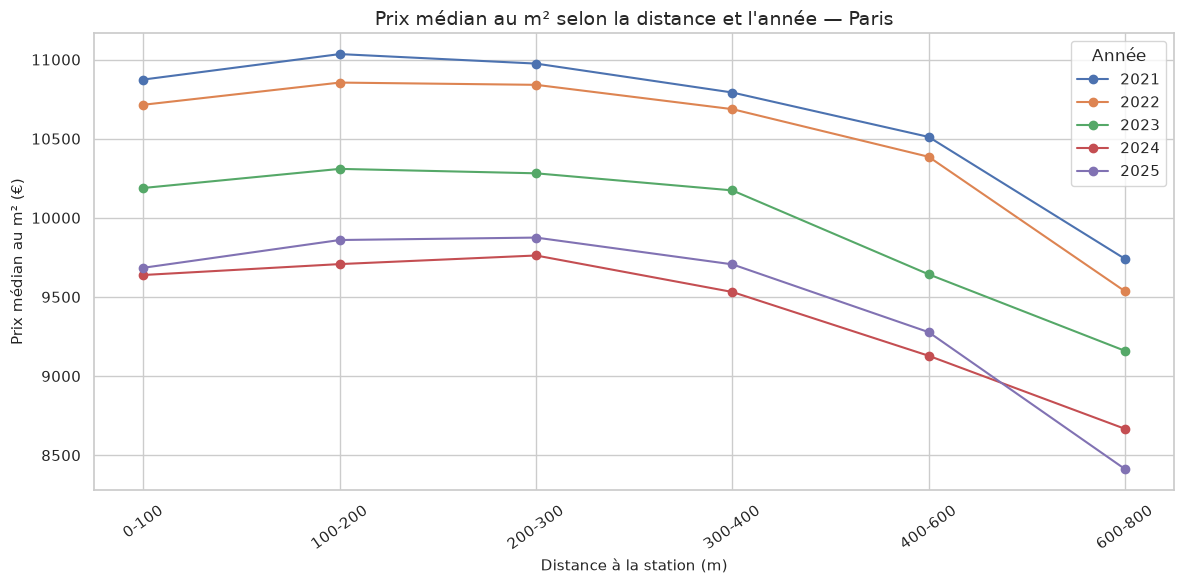

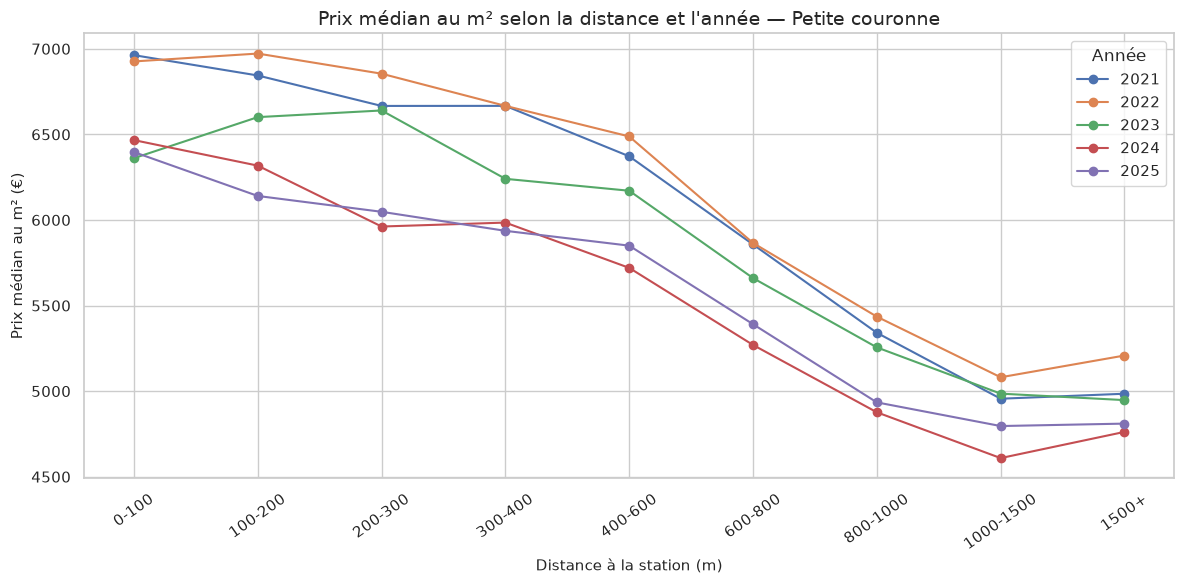

In [42]:
analyse_annuelle = (
    df.groupby(["zone", "annee", "tranche_100m"], observed=False)
      .agg(
          nombre_transactions=("prix_m2", "count"),
          prix_median=("prix_m2", "median")
      )
      .reset_index()
)

for zone in ["Paris", "Petite couronne"]:
    temp = analyse_annuelle[
        (analyse_annuelle["zone"] == zone)
        & (analyse_annuelle["nombre_transactions"] > 0)
    ]

    fig, ax = plt.subplots(figsize=(12, 6))

    for annee in sorted(temp["annee"].dropna().unique()):
        serie = temp[temp["annee"] == annee]

        ax.plot(
            serie["tranche_100m"].astype(str),
            serie["prix_median"],
            marker="o",
            label=str(int(annee))
        )

    ax.set_title(f"Prix médian au m² selon la distance et l'année — {zone}")
    ax.set_xlabel("Distance à la station (m)")
    ax.set_ylabel("Prix médian au m² (€)")
    ax.tick_params(axis="x", rotation=35)
    ax.legend(title="Année")

    plt.tight_layout()
    plt.show()

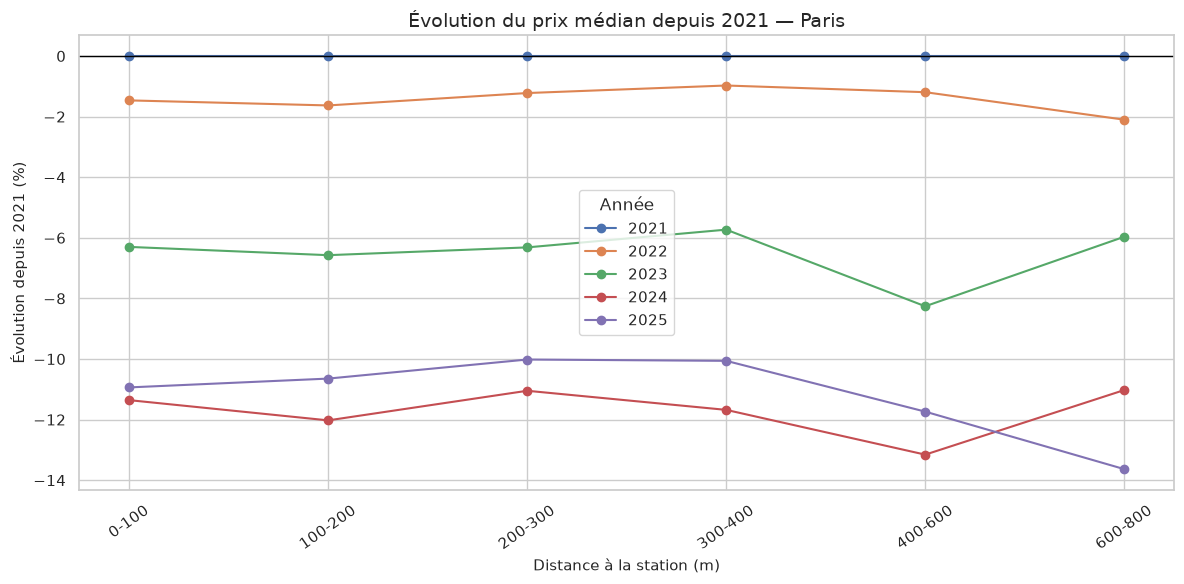

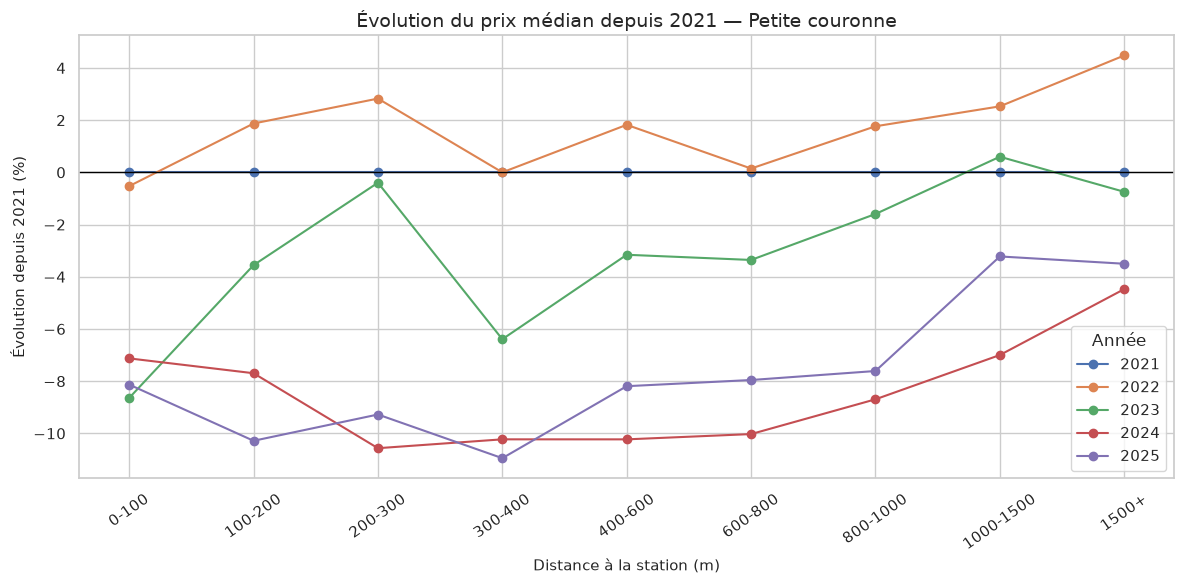

In [43]:
base_2021 = analyse_annuelle[
    analyse_annuelle["annee"] == 2021
][["zone", "tranche_100m", "prix_median"]].rename(
    columns={"prix_median": "prix_median_2021"}
)

evolution_relative = analyse_annuelle.merge(
    base_2021,
    on=["zone", "tranche_100m"],
    how="left"
)

evolution_relative["evolution_depuis_2021_pct"] = (
    evolution_relative["prix_median"]
    / evolution_relative["prix_median_2021"] - 1
) * 100

for zone in ["Paris", "Petite couronne"]:
    temp = evolution_relative[
        (evolution_relative["zone"] == zone)
        & (evolution_relative["nombre_transactions"] > 0)
    ]

    fig, ax = plt.subplots(figsize=(12, 6))

    for annee in sorted(temp["annee"].dropna().unique()):
        serie = temp[temp["annee"] == annee]

        ax.plot(
            serie["tranche_100m"].astype(str),
            serie["evolution_depuis_2021_pct"],
            marker="o",
            label=str(int(annee))
        )

    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(f"Évolution du prix médian depuis 2021 — {zone}")
    ax.set_xlabel("Distance à la station (m)")
    ax.set_ylabel("Évolution depuis 2021 (%)")
    ax.tick_params(axis="x", rotation=35)
    ax.legend(title="Année")

    plt.tight_layout()
    plt.show()

### 9.1. Une relation observée dans un marché immobilier en évolution

Les comparaisons annuelles permettent de distinguer deux dimensions : le niveau général des prix et leur variation selon la distance aux stations.

À Paris, les prix médians restent particulièrement élevés dans les premières centaines de mètres, avec une position favorable des tranches situées entre 100 et 300 mètres. La hiérarchie exacte des tranches peut cependant varier selon les années.

En petite couronne, les prix médians les plus élevés se situent généralement dans les premières tranches de distance, même si des variations apparaissent selon les années.

Les évolutions relatives à 2021 permettent également de constater que les différentes tranches ne suivent pas nécessairement des trajectoires parfaitement identiques.

Il faut toutefois éviter d'interpréter ces écarts comme une évolution de la prime de proximité au sens causal. Les prix médians sont calculés sur des transactions différentes d'une année à l'autre : les caractéristiques des logements vendus et leur localisation peuvent donc varier.

### 10. Analyse intra-communale : dépasser les différences entre territoires

Une comparaison directe entre Paris et la petite couronne peut être influencée par les différences structurelles entre les territoires. Les niveaux de prix ne sont pas comparables d'une commune à l'autre, et les communes les plus chères ne présentent pas nécessairement la même répartition des transactions autour des stations.

Pour approfondir l'analyse, nous comparons donc les prix observés à différentes distances à l'intérieur d'une même commune.

Le principe consiste à calculer, pour chaque commune, le prix médian au mètre carré dans chaque tranche de distance, puis à le comparer à une zone de référence située entre 200 et 400 mètres.

L'écart relatif est défini par :

\[
Écart_{c,d} =
\left(
\frac{Médiane_{c,d}}{Médiane_{c,ref}}-1
\right)\times100
\]

où \(c\) désigne une commune, \(d\) une tranche de distance et \(ref\) la zone de référence.

Un écart positif indique que le prix médian de la tranche étudiée est supérieur à celui de la zone de référence de la même commune. Un écart négatif indique l'inverse.

Cette approche réduit l'influence des différences de niveau de prix entre communes. Elle ne permet cependant pas de neutraliser les différences entre quartiers, rues, bâtiments ou caractéristiques des appartements à l'intérieur d'une même commune.

In [44]:
df["code_commune"] = (
    df["code_commune"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
)

df["commune_id"] = (
    df["code_departement"].astype(str)
    + "_"
    + df["code_commune"].astype(str)
)

if "nom_commune" in df.columns:
    df["commune_label"] = (
        df["nom_commune"].fillna("Commune inconnue").astype(str)
        + " ("
        + df["code_departement"].astype(str)
        + ")"
    )
else:
    df["commune_label"] = df["commune_id"]

print("Nombre de communes distinctes :", df["commune_id"].nunique())

Nombre de communes distinctes : 142


In [45]:
# Tranches de 50 mètres jusqu'à 1 000 m
edges_commune = list(range(0, 1001, 50)) + [np.inf]
labels_commune = [
    f"{edges_commune[i]}-{edges_commune[i+1]}"
    for i in range(len(edges_commune)-1)
]
labels_commune[-1] = "1000+"

df["tranche_commune"] = pd.cut(
    df["dist_station_m"],
    bins=edges_commune,
    labels=labels_commune,
    right=False,
    include_lowest=True
)

stats_commune = (
    df.groupby(
        ["zone", "commune_id", "commune_label", "tranche_commune"],
        observed=False
    )
    .agg(
        nombre_transactions=("prix_m2", "count"),
        prix_median=("prix_m2", "median")
    )
    .reset_index()
)

# Zone de référence : 200 à 400 mètres
reference = (
    df[df["dist_station_m"].between(200, 400, inclusive="left")]
    .groupby(["commune_id", "commune_label", "zone"])
    .agg(
        prix_reference=("prix_m2", "median"),
        n_reference=("prix_m2", "count")
    )
    .reset_index()
)

stats_commune = stats_commune.merge(
    reference,
    on=["commune_id", "commune_label", "zone"],
    how="left"
)

stats_commune["ecart_relatif_pct"] = (
    stats_commune["prix_median"]
    / stats_commune["prix_reference"] - 1
) * 100

# Seuil minimal d'effectifs dans la tranche et la référence
SEUIL_EFFECTIF = 30

stats_commune_valides = stats_commune[
    (stats_commune["nombre_transactions"] >= SEUIL_EFFECTIF)
    & (stats_commune["n_reference"] >= SEUIL_EFFECTIF)
    & stats_commune["prix_reference"].notna()
].copy()

display(stats_commune_valides.head())

,zone,commune_id,commune_label,tranche_commune,nombre_transactions,prix_median,prix_reference,n_reference,ecart_relatif_pct
1,Paris,75_75101,Paris 1er Arrondissement (75),50-100,147,"12,379.81","13,500.00",367.00,-8.30
2,Paris,75_75101,Paris 1er Arrondissement (75),100-150,370,"12,517.14","13,500.00",367.00,-7.28
3,Paris,75_75101,Paris 1er Arrondissement (75),150-200,484,"12,624.23","13,500.00",367.00,-6.49
4,Paris,75_75101,Paris 1er Arrondissement (75),200-250,203,"13,055.56","13,500.00",367.00,-3.29
5,Paris,75_75101,Paris 1er Arrondissement (75),250-300,53,"13,735.10","13,500.00",367.00,1.74


In [46]:
synthese_intra = (
    stats_commune_valides
    .groupby(["zone", "tranche_commune"], observed=False)
    .agg(
        nombre_communes=("commune_id", "nunique"),
        ecart_median_pct=("ecart_relatif_pct", "median"),
        ecart_moyen_pct=("ecart_relatif_pct", "mean"),
        part_communes_positives=(
            "ecart_relatif_pct",
            lambda x: (x > 0).mean() * 100
        )
    )
    .reset_index()
)

display(synthese_intra)

,zone,tranche_commune,nombre_communes,ecart_median_pct,ecart_moyen_pct,part_communes_positives
0,Paris,0-50,18,0.62,-0.35,50.00
1,Paris,50-100,20,-1.36,-1.28,30.00
2,Paris,100-150,20,-0.80,-0.79,45.00
3,Paris,150-200,20,-0.72,-1.58,35.00
4,Paris,200-250,20,-0.20,-0.50,45.00
5,Paris,250-300,20,0.42,0.75,50.00
6,Paris,300-350,19,0.46,1.03,68.42
7,Paris,350-400,19,-0.39,0.53,42.11
8,Paris,400-450,15,-0.66,-0.25,33.33
9,Paris,450-500,12,0.18,1.10,50.00


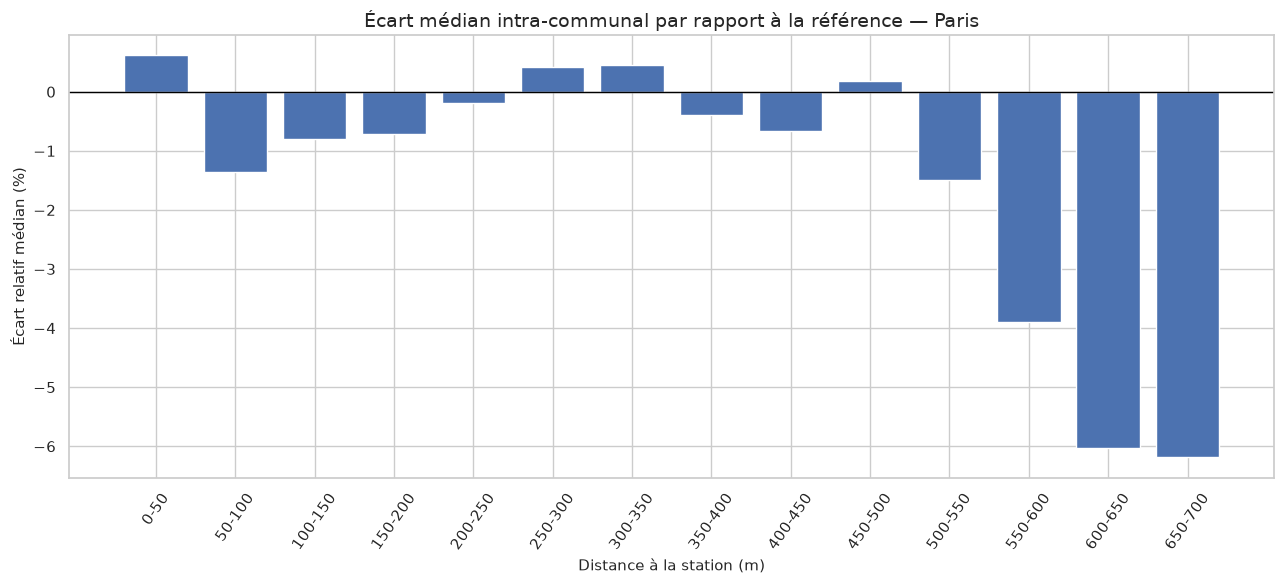

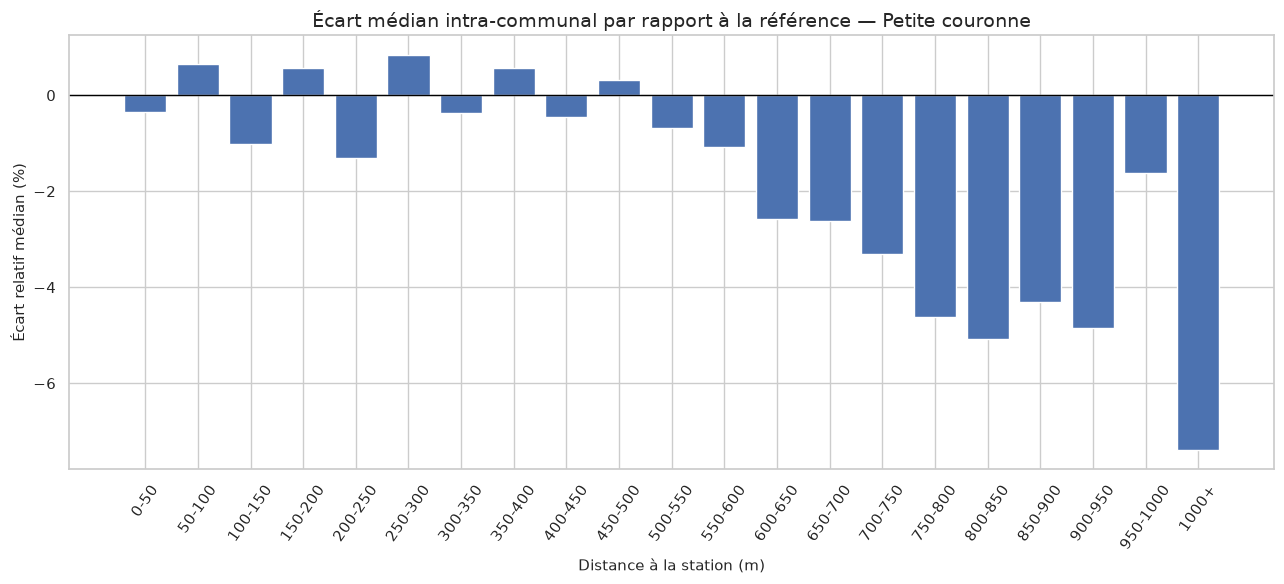

In [47]:
for zone in ["Paris", "Petite couronne"]:
    temp = synthese_intra[
        (synthese_intra["zone"] == zone)
        & (synthese_intra["nombre_communes"] > 0)
    ].copy()

    fig, ax = plt.subplots(figsize=(13, 6))

    ax.bar(
        temp["tranche_commune"].astype(str),
        temp["ecart_median_pct"]
    )

    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(
        f"Écart médian intra-communal par rapport à la référence — {zone}"
    )
    ax.set_xlabel("Distance à la station (m)")
    ax.set_ylabel("Écart relatif médian (%)")
    ax.tick_params(axis="x", rotation=55)

    plt.tight_layout()
    plt.show()

### 10.1. Une forte hétérogénéité entre communes

L'analyse intra-communale permet de compléter les comparaisons globales.

Les résultats montrent que les écarts relatifs aux prix de référence ne sont pas identiques d'une commune à l'autre. Certaines communes présentent des écarts positifs à proximité des stations, tandis que d'autres enregistrent des écarts négatifs.

À Paris, les résultats peuvent notamment varier selon les arrondissements. En petite couronne, les situations sont également hétérogènes : la proximité immédiate peut être favorable dans certaines communes et moins valorisée dans d'autres.

Cette hétérogénéité est importante pour l'interprétation. Elle indique qu'une relation observée à l'échelle globale ne se retrouve pas nécessairement de manière uniforme dans chaque commune.

La comparaison intra-communale constitue donc un approfondissement utile, mais elle ne doit pas être considérée comme une comparaison parfaitement homogène. Les quartiers, les caractéristiques des immeubles, l'environnement immédiat et la composition des transactions restent différents à l'intérieur d'une même commune.

### 11. Recherche descriptive d'intervalles de distance particulièrement valorisés

L'objectif de cette étape est d'aller au-delà de la simple identification de la tranche présentant le prix médian le plus élevé.

Un maximum ponctuel peut être influencé par la composition de l'échantillon ou par un nombre limité de transactions. Nous cherchons donc à déterminer si plusieurs tranches consécutives présentent des écarts intra-communaux positifs.

Pour chaque tranche, trois indicateurs sont examinés :

- l'écart relatif médian entre communes par rapport à la zone de référence ;
- la proportion de communes présentant un écart positif ;
- le nombre de communes effectivement représentées.

Une tranche sera considérée comme présentant un signal descriptif favorable si son écart relatif médian est positif et si plus de la moitié des communes représentées présentent également un écart positif. Un nombre minimal de communes est exigé afin d'éviter de tirer des conclusions à partir d'un échantillon trop restreint.

Nous recherchons ensuite des séquences de tranches consécutives satisfaisant ces critères.

Il ne s'agit pas de déterminer une distance optimale au sens économique ou causal, mais d'identifier des intervalles dans lesquels les prix observés sont relativement plus élevés que ceux de la zone de référence au sein des communes concernées.

In [54]:
def calculer_synthese_intra(seuil):

    temp = stats_commune.copy()

    temp = temp[
        (temp["nombre_transactions"] >= seuil)
        & (temp["n_reference"] >= seuil)
        & temp["prix_reference"].notna()
        & (temp["prix_reference"] > 0)
    ].copy()

    temp["ecart_relatif_pct"] = (
        temp["prix_median"] / temp["prix_reference"] - 1
    ) * 100

    synthese = (
        temp.groupby(["zone", "tranche_commune"], observed=False)
        .agg(
            nombre_communes=("commune_id", "nunique"),
            ecart_median_pct=("ecart_relatif_pct", "median"),
            ecart_moyen_pct=("ecart_relatif_pct", "mean"),
            part_communes_positives=(
                "ecart_relatif_pct",
                lambda x: (x > 0).mean() * 100
            )
        )
        .reset_index()
    )

    synthese["seuil_effectif"] = seuil

    return synthese


seuils = [20, 30, 50, 100]

resultats_robustesse = pd.concat(
    [calculer_synthese_intra(s) for s in seuils],
    ignore_index=True
)

display(resultats_robustesse)

,zone,tranche_commune,nombre_communes,ecart_median_pct,ecart_moyen_pct,part_communes_positives,seuil_effectif
0,Paris,0-50,19,-0.28,-0.35,47.37,20
1,Paris,50-100,20,-1.36,-1.28,30.00,20
2,Paris,100-150,20,-0.80,-0.79,45.00,20
3,Paris,150-200,20,-0.72,-1.58,35.00,20
4,Paris,200-250,20,-0.20,-0.50,45.00,20
...,...,...,...,...,...,...,...
163,Petite couronne,800-850,17,-1.90,-0.24,41.18,100
164,Petite couronne,850-900,14,-5.41,-5.47,35.71,100
165,Petite couronne,900-950,13,-3.86,-3.50,38.46,100
166,Petite couronne,950-1000,12,-4.68,-1.84,41.67,100


In [50]:
def detecter_intervalles(synthese, seuil):
    """
    Détecte les séquences de tranches consécutives qui satisfont
    les critères descriptifs retenus.
    """

    resultats = []

    for zone in ["Paris", "Petite couronne"]:

        temp = synthese[
            (synthese["zone"] == zone)
            & (synthese["seuil_effectif"] == seuil)
        ].copy()

        minimum_communes = 10 if zone == "Paris" else 20

        temp = temp[
            (temp["nombre_communes"] >= minimum_communes)
            & (temp["ecart_median_pct"] > 0)
            & (temp["part_communes_positives"] > 50)
        ].copy()

        # Les intervalles 50 m sont ordonnés par leur borne inférieure
        temp["borne_inf"] = (
            temp["tranche_commune"].astype(str)
            .str.extract(r"^(\d+)-")[0]
            .astype(float)
        )

        temp["borne_sup"] = (
            temp["tranche_commune"].astype(str)
            .str.extract(r"^\d+-(\d+)$")[0]
            .astype(float)
        )

        temp = temp.dropna(subset=["borne_inf", "borne_sup"])
        temp = temp.sort_values("borne_inf")

        if temp.empty:
            continue

        sequence = []
        borne_sup_precedente = None

        for _, ligne in temp.iterrows():

            debut = ligne["borne_inf"]
            fin = ligne["borne_sup"]

            if (
                borne_sup_precedente is None
                or debut == borne_sup_precedente
            ):
                sequence.append(ligne)
            else:
                if len(sequence) >= 2:
                    resultats.append(
                        construire_resume_sequence(
                            sequence, zone, seuil
                        )
                    )

                sequence = [ligne]

            borne_sup_precedente = fin

        if len(sequence) >= 2:
            resultats.append(
                construire_resume_sequence(
                    sequence, zone, seuil
                )
            )

    return pd.DataFrame(resultats)


def construire_resume_sequence(sequence, zone, seuil):
    temp = pd.DataFrame(sequence)

    return {
        "zone": zone,
        "seuil_effectif": seuil,
        "debut_intervalle_m": int(temp["borne_inf"].min()),
        "fin_intervalle_m": int(temp["borne_sup"].max()),
        "nombre_tranches_consecutives": len(temp),
        "ecart_median_moyen_pct": temp["ecart_median_pct"].mean(),
        "part_positive_moyenne_pct": temp[
            "part_communes_positives"
        ].mean(),
        "nombre_communes_median": temp[
            "nombre_communes"
        ].median()
    }


intervalles_detectes = pd.concat(
    [
        detecter_intervalles(resultats_robustesse, seuil)
        for seuil in seuils
    ],
    ignore_index=True
)

display(intervalles_detectes)

""


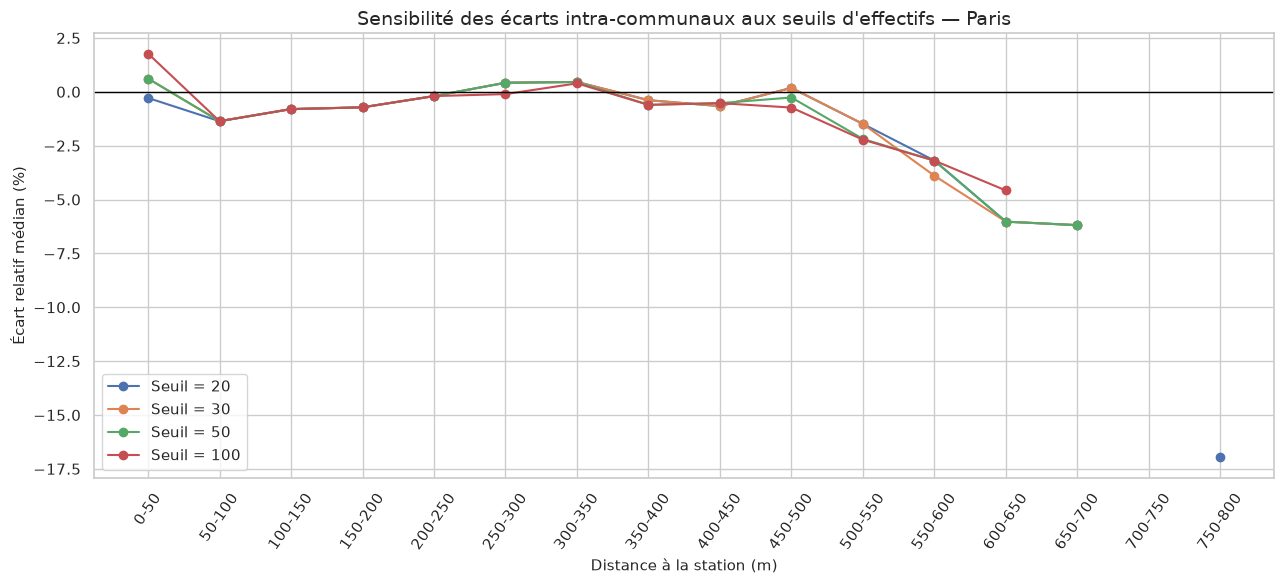

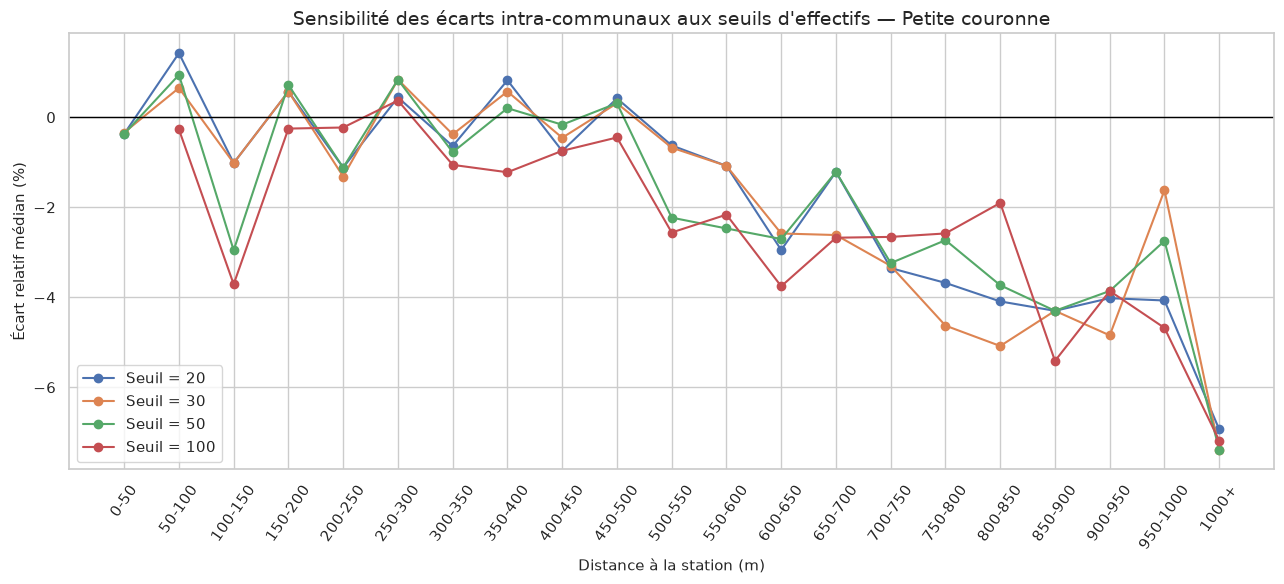

In [51]:
for zone in ["Paris", "Petite couronne"]:

    temp = resultats_robustesse[
        resultats_robustesse["zone"] == zone
    ].copy()

    fig, ax = plt.subplots(figsize=(13, 6))

    for seuil in seuils:
        serie = temp[temp["seuil_effectif"] == seuil]

        ax.plot(
            serie["tranche_commune"].astype(str),
            serie["ecart_median_pct"],
            marker="o",
            label=f"Seuil = {seuil}"
        )

    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(
        f"Sensibilité des écarts intra-communaux aux seuils d'effectifs — {zone}"
    )
    ax.set_xlabel("Distance à la station (m)")
    ax.set_ylabel("Écart relatif médian (%)")
    ax.tick_params(axis="x", rotation=55)
    ax.legend()

    plt.tight_layout()
    plt.show()

### 11.1. Sensibilité des résultats aux seuils d'effectifs

Les analyses précédentes reposent sur des effectifs minimaux afin de limiter l'influence des groupes comportant trop peu de transactions.

Toutefois, le choix du seuil peut modifier les communes retenues et, par conséquent, les écarts relatifs calculés.

Nous comparons donc plusieurs seuils d'effectifs : 20, 30, 50 et 100 transactions. Cette démarche permet de vérifier si les tendances observées persistent lorsque l'on exige des groupes plus importants.

Un intervalle qui reste favorable pour plusieurs seuils constitue un résultat descriptif plus convaincant qu'un intervalle qui n'apparaît que pour un seuil particulier.

À l'inverse, si les intervalles identifiés varient fortement, cela indique que les conclusions dépendent de la composition de l'échantillon et doivent être formulées avec davantage de prudence.

La stabilité d'un intervalle dans cette analyse ne démontre cependant pas l'existence d'une distance optimale universelle. Elle indique seulement que le signal descriptif est relativement moins sensible au choix du seuil d'effectifs.

### 12. Limites et précautions d'interprétation

Malgré la richesse des données et la diversité des analyses descriptives, plusieurs limites doivent être prises en compte.

**1. Une relation descriptive et non causale**

Les résultats mettent en évidence une association entre la distance à une station et les prix observés. Ils ne permettent pas d'affirmer que la proximité des transports provoque directement une augmentation ou une diminution du prix des appartements.

**2. Des caractéristiques immobilières différentes**

Deux appartements situés à des distances différentes d'une station peuvent également différer par leur surface, leur état, leur étage, leur ancienneté, leur environnement ou leur qualité. Ces caractéristiques peuvent contribuer aux écarts de prix observés.

**3. Une hétérogénéité géographique importante**

Paris et la petite couronne présentent des structures urbaines et des marchés immobiliers différents. Même à l'intérieur d'une commune, les quartiers et les environnements immédiats peuvent être très hétérogènes.

**4. Des effectifs variables selon les distances**

Les transactions ne sont pas réparties uniformément autour des stations. À Paris, les ventes sont particulièrement concentrées dans les premières centaines de mètres. Les résultats sur les distances les plus élevées reposent donc sur des effectifs plus faibles, voire inexistants.

**5. Une composition des transactions qui évolue dans le temps**

Les transactions observées ne concernent pas nécessairement les mêmes types de biens d'une année à l'autre. Les évolutions temporelles des prix médians peuvent donc refléter à la fois les mouvements du marché et les changements dans la composition des ventes.

**6. Une mesure simplifiée de l'accessibilité**

La distance utilisée correspond à la distance géographique retenue dans la base enrichie. Elle ne représente pas nécessairement le temps réel de marche, la qualité du réseau, la fréquence des transports ou le nombre de destinations accessibles.

Ces limites invitent à interpréter les résultats comme des régularités observées dans les transactions étudiées, et non comme une mesure isolée de la valeur économique des transports en commun.

# 13. Conclusion générale

Cette étude avait pour objectif d'examiner la relation entre la proximité des stations de transport en commun et les prix de vente des appartements à Paris et en petite couronne, à partir des transactions observées entre 2021 et 2025.

Les différentes analyses descriptives mettent en évidence une association entre distance à la station et prix au mètre carré. Dans l'ensemble, les prix médians sont plus élevés à proximité des stations et tendent à diminuer lorsque la distance augmente. Cette évolution n'est toutefois ni parfaitement régulière ni identique dans les deux territoires étudiés.

À Paris, les prix médians les plus élevés sont observés dans les premières centaines de mètres, avec un maximum dans la tranche de 100 à 200 mètres lorsque l'on utilise un découpage en tranches de 100 mètres. L'analyse plus fine confirme que les prix restent particulièrement élevés autour de 100 à 250 mètres. Ces résultats suggèrent une zone de forte valorisation à proximité des stations, plutôt qu'un avantage systématique à être situé immédiatement à côté de celles-ci.

En petite couronne, les prix médians les plus élevés apparaissent dans la tranche de 0 à 100 mètres. La diminution des prix avec l'éloignement est plus progressive et se poursuit sur des distances plus importantes. Les variations observées à très courte distance montrent néanmoins que la relation n'est pas strictement monotone.

L'analyse temporelle indique que ces profils généraux se retrouvent dans les différentes années, même si les niveaux de prix et la hiérarchie précise des tranches varient. L'étude intra-communale apporte un éclairage complémentaire : les écarts relatifs à une zone de référence diffèrent sensiblement selon les communes. La proximité des transports ne se traduit donc pas par une valorisation uniforme sur l'ensemble du territoire.

Enfin, la recherche d'intervalles favorables souligne l'intérêt de dépasser la seule identification d'une tranche présentant le prix médian le plus élevé. La stabilité des écarts intra-communaux, leur répartition entre communes et leur sensibilité aux seuils d'effectifs constituent des éléments essentiels pour juger de la solidité des résultats.

**En définitive, il n'existe pas, dans les données étudiées, une distance optimale unique qui s'imposerait à Paris et en petite couronne.** Les résultats suggèrent plutôt des profils de valorisation différents selon les territoires : une zone de prix particulièrement élevés autour de 100 à 300 mètres à Paris, et une valorisation plus forte dans la proximité immédiate en petite couronne.

Cette étude met ainsi en évidence l'importance de considérer conjointement la distance, le contexte territorial, la granularité de l'analyse et la composition des transactions. Elle fournit une description empirique des relations observées entre accessibilité aux transports et prix immobiliers, tout en rappelant que ces relations ne peuvent être interprétées comme des effets causaux isolés.

In [52]:
OUTPUT_DIR = Path("resultats_notebook")
OUTPUT_DIR.mkdir(exist_ok=True)

analyse_100.to_csv(
    OUTPUT_DIR / "prix_distance_100m.csv",
    index=False,
    encoding="utf-8-sig"
)

analyse_50.to_csv(
    OUTPUT_DIR / "prix_distance_50m.csv",
    index=False,
    encoding="utf-8-sig"
)

analyse_annuelle.to_csv(
    OUTPUT_DIR / "prix_distance_annuel.csv",
    index=False,
    encoding="utf-8-sig"
)

stats_commune_valides.to_csv(
    OUTPUT_DIR / "ecarts_intra_communaux.csv",
    index=False,
    encoding="utf-8-sig"
)

resultats_robustesse.to_csv(
    OUTPUT_DIR / "robustesse_seuils.csv",
    index=False,
    encoding="utf-8-sig"
)

intervalles_detectes.to_csv(
    OUTPUT_DIR / "intervalles_favorables.csv",
    index=False,
    encoding="utf-8-sig"
)

print(f"Résultats exportés dans : {OUTPUT_DIR.resolve()}")

Résultats exportés dans : /home/onyxia/work/Projet_Data_2A_S1/notebooks/resultats_notebook


In [53]:
print("Bilan final du notebook")
print("=" * 55)

print(f"Transactions analysées : {len(df):,}")
print(f"Communes représentées : {df['commune_id'].nunique():,}")
print(f"Période : {int(df['annee'].min())}–{int(df['annee'].max())}")

print("\nRépartition des transactions :")
display(
    df.groupby(["zone", "annee"])
      .size()
      .unstack(fill_value=0)
)

print("\nFichiers produits :")
for fichier in sorted(OUTPUT_DIR.glob("*.csv")):
    print("-", fichier.name)

Bilan final du notebook
Transactions analysées : 319,947
Communes représentées : 142
Période : 2021–2025

Répartition des transactions :


annee,2021,2022,2023,2024,2025
zone,,,,,
Paris,30427,33138,26861,24460,28356
Petite couronne,41244,41669,32013,27911,33868



Fichiers produits :
- ecarts_intra_communaux.csv
- intervalles_favorables.csv
- prix_distance_100m.csv
- prix_distance_50m.csv
- prix_distance_annuel.csv
- robustesse_seuils.csv


=== Comparaison prix/m² (EUR) à tranche de distance égale : METRO vs RER ===


/tmp/ipykernel_59292/1476413342.py:52: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  summary_dist["ecart_mediane_RER_vs_METRO"] = summary_dist[("mediane", "RER")] - summary_dist[("mediane", "METRO")]
/tmp/ipykernel_59292/1476413342.py:53: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  summary_dist["ratio_mediane_RER_sur_METRO"] = summary_dist[("mediane", "RER")] / summary_dist[("mediane", "METRO")]


n          mediane            moyenne               iqr  \
mode_station  METRO    RER     METRO      RER     METRO      RER    METRO   
tranche_dist                                                                
0-200m        63334   4985 10,058.82 6,234.04 10,259.35 7,282.81 3,479.59   
200-400m      84064  13541  9,714.29 5,650.00  9,856.17 6,657.65 3,683.70   
400-600m      32455  13120  8,136.36 5,153.85  8,231.64 5,625.03 3,815.06   
600-800m      13235  11870  6,881.58 4,640.31  7,068.95 4,874.62 3,412.56   
800-1000m      7659  10217  6,489.36 4,302.33  6,650.74 4,525.31 3,404.08   
1000-1500m     9434  17474  6,458.33 4,140.31  6,413.57 4,395.34 2,684.98   
1500m+         9251  17464  5,867.57 4,073.17  5,858.60 4,310.35 2,199.72   

                      ecart_mediane_RER_vs_METRO ratio_mediane_RER_sur_METRO  
mode_station      RER                                                         
tranche_dist                                                                  
0-200m       5,449.33                  -3,824.78                        0.62  
200-400m     3,712.91                  -4,064.29                        0.58  
400-600m     2,682.20                  -2,982.52                        0.63  
600-800m     2,383.64                  -2,241.27                        0.67  
800-1000m    2,398.31                  -2,187.04                        0.66  
1000-1500m   2,161.06                  -2,318.02                        0.64  
1500m+       2,332.83                  -1,794.40                        0.69

METRO | n=219,432 | médiane 0-200m=10,059 € | médiane 600-800m=6,882 € | pente brute=-254.0 € / 100m
RER   | n= 88,671 | médiane 0-200m=6,234 € | médiane 600-800m=4,640 € | pente brute=-101.5 € / 100m


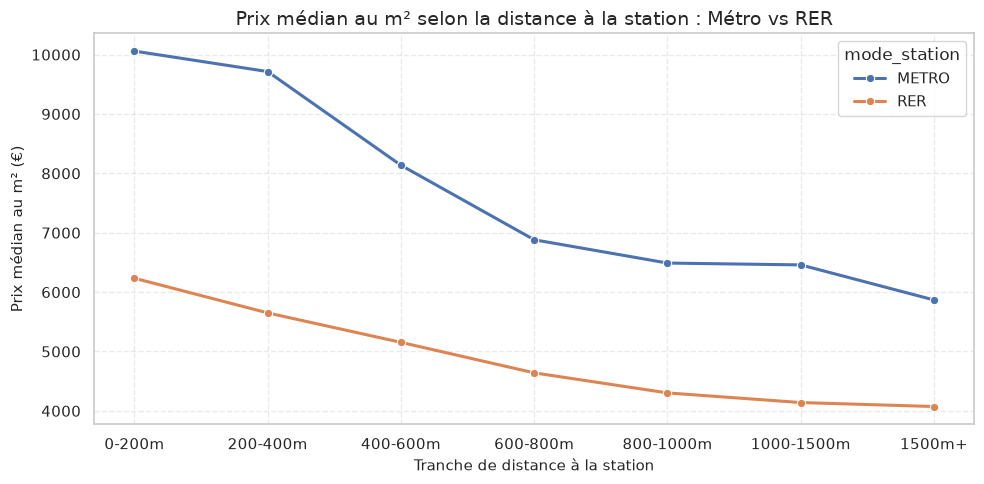

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extraction propre du mode principal / exclusif depuis `modes_station`
def extract_mode(val):
    if pd.isna(val):
        return np.nan
    s = str(val).upper()
    has_metro = "METRO" in s or "MÉTRO" in s
    has_rer = "RER" in s
    has_tram = "TRAM" in s
    has_train = "TRAIN" in s or "TRANSILIEN" in s

    modes_present = [m for m, flag in [
        ("METRO", has_metro),
        ("RER", has_rer),
        ("TRAM", has_tram),
        ("TRAIN", has_train),
    ] if flag]

    if len(modes_present) == 1:
        return modes_present[0]
    elif len(modes_present) > 1:
        return "MULTI_MODE"
    return "AUTRE"

df_mode = df.copy()
df_mode["mode_station"] = df_mode["modes_station"].apply(extract_mode)

# Filtre sur Métro vs RER exclusifs (et distance renseignée)
df_mr = df_mode[
    df_mode["mode_station"].isin(["METRO", "RER"])
    & df_mode["dist_station_m"].notna()
    & df_mode["prix_m2"].notna()
].copy()

# Tranches de distance égales (ex. tous les 200 m jusqu'à 1600 m+, ou réutiliser `tranche_100m`)
bins = [0, 200, 400, 600, 800, 1000, 1500, np.inf]
labels = ["0-200m", "200-400m", "400-600m", "600-800m", "800-1000m", "1000-1500m", "1500m+"]
df_mr["tranche_dist"] = pd.cut(df_mr["dist_station_m"], bins=bins, labels=labels, right=False)

# 2. Comparaison à distance égale (médiane, moyenne, effectifs, écart RER - METRO)
summary_dist = (
    df_mr.groupby(["tranche_dist", "mode_station"], observed=False)["prix_m2"]
    .agg(n="count", mediane="median", moyenne="mean", iqr=lambda x: np.percentile(x, 75) - np.percentile(x, 25))
    .unstack("mode_station")
)

# Écart de médiane et de moyenne entre RER et METRO à tranche de distance égale
summary_dist["ecart_mediane_RER_vs_METRO"] = summary_dist[("mediane", "RER")] - summary_dist[("mediane", "METRO")]
summary_dist["ratio_mediane_RER_sur_METRO"] = summary_dist[("mediane", "RER")] / summary_dist[("mediane", "METRO")]

print("=== Comparaison prix/m² (EUR) à tranche de distance égale : METRO vs RER ===")
display(summary_dist.round(2))

# 3. Sensibilité à la distance (variation de prix/m² entre tranches proches & pente linéaire simple)
for mode in ["METRO", "RER"]:
    sub = df_mr[df_mr["mode_station"] == mode]
    # Variation médiane entre 0-200m et 600-800m (si effectifs suffisants)
    m_proche = sub[sub["tranche_dist"] == "0-200m"]["prix_m2"].median()
    m_loin = sub[sub["tranche_dist"] == "600-800m"]["prix_m2"].median()
    # Pente brute OLS (EUR/m² par 100 mètres de distance)
    slope_100m = np.polyfit(sub["dist_station_m"] / 100.0, sub["prix_m2"], 1)[0]
    print(
        f"{mode:5s} | n={len(sub):7,d} | médiane 0-200m={m_proche:,.0f} € | "
        f"médiane 600-800m={m_loin:,.0f} € | pente brute={slope_100m:+.1f} € / 100m"
    )

# 4. Visualisation : Médianes par tranche de distance égale
med_plot = (
    df_mr.groupby(["tranche_dist", "mode_station"], observed=False)["prix_m2"]
    .median()
    .reset_index()
)
counts_plot = (
    df_mr.groupby(["tranche_dist", "mode_station"], observed=False)["prix_m2"]
    .count()
    .reset_index(name="n")
)
med_plot = med_plot.merge(counts_plot, on=["tranche_dist", "mode_station"])
# Masquer les points avec très peu d'observations (ex. < 30) pour éviter le bruit
med_plot_clean = med_plot[med_plot["n"] >= 30]

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=med_plot_clean,
    x="tranche_dist",
    y="prix_m2",
    hue="mode_station",
    marker="o",
    linewidth=2.2,
)
plt.title("Prix médian au m² selon la distance à la station : Métro vs RER")
plt.xlabel("Tranche de distance à la station")
plt.ylabel("Prix médian au m² (€)")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### Comparaison de l'effet de la distance selon le mode de transport (Métro vs RER)

L'analyse comparative des prix médians au m² à tranches de distance égales met en évidence deux phénomènes complémentaires : **l'écart de niveau de prix** entre les deux modes et **la sensibilité du prix à l'éloignement de la station**.

| Tranche de distance | Métro (médiane ≈) | RER (médiane ≈) | Écart absolu (Métro − RER) | Ratio (Métro / RER) |
| :--- | :---: | :---: | :---: | :---: |
| **0–200m** | ~10 060 €/m² | ~6 230 €/m² | **+3 830 €/m²** | **1,61×** |
| **200–400m** | ~9 690 €/m² | ~5 650 €/m² | **+4 040 €/m²** | **1,72×** |
| **400–600m** | ~8 140 €/m² | ~5 155 €/m² | **+2 985 €/m²** | **1,58×** |
| **600–800m** | ~6 880 €/m² | ~4 640 €/m² | **+2 240 €/m²** | **1,48×** |
| **800–1000m** | ~6 500 €/m² | ~4 300 €/m² | **+2 200 €/m²** | **1,51×** |
| **1000–1500m** | ~6 450 €/m² | ~4 135 €/m² | **+2 315 €/m²** | **1,56×** |
| **1500m+** | ~5 870 €/m² | ~4 065 €/m² | **+1 805 €/m²** | **1,44×** |

#### Principaux enseignements

1. **Un niveau de prix nettement plus élevé autour du Métro à distance égale :**
   À distance comparable de la station, les appartements situés à proximité du **Métro** affichent un prix médian supérieur de **+1 805 € à +4 040 €/m²** par rapport à ceux desservis par le **RER** (soit un facteur compris entre **1,44× et 1,72×**). Cet écart atteint son maximum dans la tranche **200–400m** (~9 690 €/m² contre ~5 650 €/m²).

2. **Une décroissance avec la distance plus marquée pour le Métro que pour le RER :**
   * **Sur l'ensemble des tranches (0–200m à 1500m+) :** la médiane recule de **−4 190 €/m² (−41,7 %)** pour le **Métro** (de ~10 060 € à ~5 870 €), contre **−2 165 €/m² (−34,8 %)** pour le **RER** (de ~6 230 € à ~4 065 €).
   * **Profil du Métro :** la baisse est particulièrement prononcée entre **200–400m et 600–800m** (−2 810 €/m², soit **−29,0 %** cumulés sur ces deux paliers), avant de se stabiliser entre **800–1000m** (~6 500 €) et **1000–1500m** (~6 450 €).
   * **Profil du RER :** la diminution est plus régulière jusqu'à **800–1000m** (entre −7 % et −10 % par tranche), puis s'aplatit nettement au-delà de **1000m** (~4 135 €/m² puis ~4 065 €/m²).

#### Limite d'interprétation (effet de composition spatiale)
Ces résultats traduisent une **association descriptive** et non un effet causal isolé du mode de transport : le réseau de **Métro** est fortement concentré à Paris et en proche couronne dense (où les valeurs foncières sont structurellement plus élevées), tandis que le **RER** couvre des territoires plus étendus et hétérogènes. La forte chute observée pour le Métro au-delà de 400–600m reflète ainsi en partie un changement de zone géographique (sortie des secteurs centraux parisiens vers la première couronne) autant que la distance proprement dite à la station.